In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from scipy.stats import ttest_ind
import scipy.stats as stats

warnings.filterwarnings("ignore")

In [22]:
from sqlalchemy import create_engine, URL
import pandas as pd

# Connect to your existing MySQL database
connection_url = URL.create(
    drivername="mysql+pymysql",
    username="root",
    password="Vaishu@23",
    host="localhost",
    port=3306,
    database="inventory"
)

engine = create_engine(connection_url)

# Test the connection
with engine.connect() as conn:
    print("MySQL connected successfully!")

MySQL connected successfully!


In [23]:
# Fetch vendor summary data from MySQL
df = pd.read_sql_query(
    "SELECT * FROM vendor_sales_summary",
    engine
)

print("Data loaded successfully from MySQL")
print("Dataset shape:", df.shape)

display(df.head())

Data loaded successfully from MySQL
Dataset shape: (10692, 18)


,VendorNumber,VendorName,Brand,Description,PurchasePrice,ActualPrice,Volume,TotalPurchaseQuantity,TotalPurchaseDollars,TotalSalesQuantity,TotalSalesDollars,TotalSalesPrice,TotalExciseTax,FreightCost,GrossProfit,ProfitMargin,StockTurnover,SalesToPurchaseRatio
0,1128,BROWN-FORMAN CORP,1233,Jack Daniels No 7 Black,26.27,36.99,1750,145080.0,3811251.60,142049.0,5.101920e+06,672819.31,260999.20,68601.68,1290667.91,25.297693,0.979108,1.338647
1,4425,MARTIGNETTI COMPANIES,3405,Tito's Handmade Vodka,23.19,28.99,1750,164038.0,3804041.22,160247.0,4.819073e+06,561512.37,294438.66,144929.24,1015032.27,21.062810,0.976890,1.266830
2,17035,PERNOD RICARD USA,8068,Absolut 80 Proof,18.24,24.99,1750,187407.0,3418303.68,187140.0,4.538121e+06,461140.15,343854.07,123780.22,1119816.92,24.675786,0.998575,1.327594
3,3960,DIAGEO NORTH AMERICA INC,4261,Capt Morgan Spiced Rum,16.17,22.99,1750,201682.0,3261197.94,200412.0,4.475973e+06,420050.01,368242.80,257032.07,1214774.94,27.139908,0.993703,1.372493
4,3960,DIAGEO NORTH AMERICA INC,3545,Ketel One Vodka,21.89,29.99,1750,138109.0,3023206.01,135838.0,4.223108e+06,545778.28,249587.83,257032.07,1199901.61,28.412764,0.983556,1.396897


In [24]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
VendorNumber,10692.0,10650.649458,18753.519148,2.000000,3951.000000,7153.000000,9552.000000,2.013590e+05
Brand,10692.0,18039.228769,12662.187074,58.000000,5793.500000,18761.500000,25514.250000,9.063100e+04
PurchasePrice,10692.0,24.385303,109.269375,0.360000,6.840000,10.455000,19.482500,5.681810e+03
ActualPrice,10692.0,35.643671,148.246016,0.490000,10.990000,15.990000,28.990000,7.499990e+03
TotalPurchaseQuantity,10692.0,3140.886831,11095.086769,1.000000,36.000000,262.000000,1975.750000,3.376600e+05
TotalPurchaseDollars,10692.0,30106.693372,123067.799627,0.710000,453.457500,3655.465000,20738.245000,3.811252e+06
TotalSalesQuantity,10514.0,3129.583317,11037.801407,1.000000,36.000000,280.000000,1985.000000,3.349390e+05
TotalSalesDollars,10514.0,42954.173834,168977.755843,1.980000,809.820000,5599.700000,29524.250000,5.101920e+06
TotalSalesPrice,10514.0,19111.958773,45264.605387,0.990000,334.890000,3020.085000,16442.477500,6.728193e+05
TotalExciseTax,10514.0,1804.263569,11065.659557,0.060000,5.382500,50.425000,436.730000,3.682428e+05


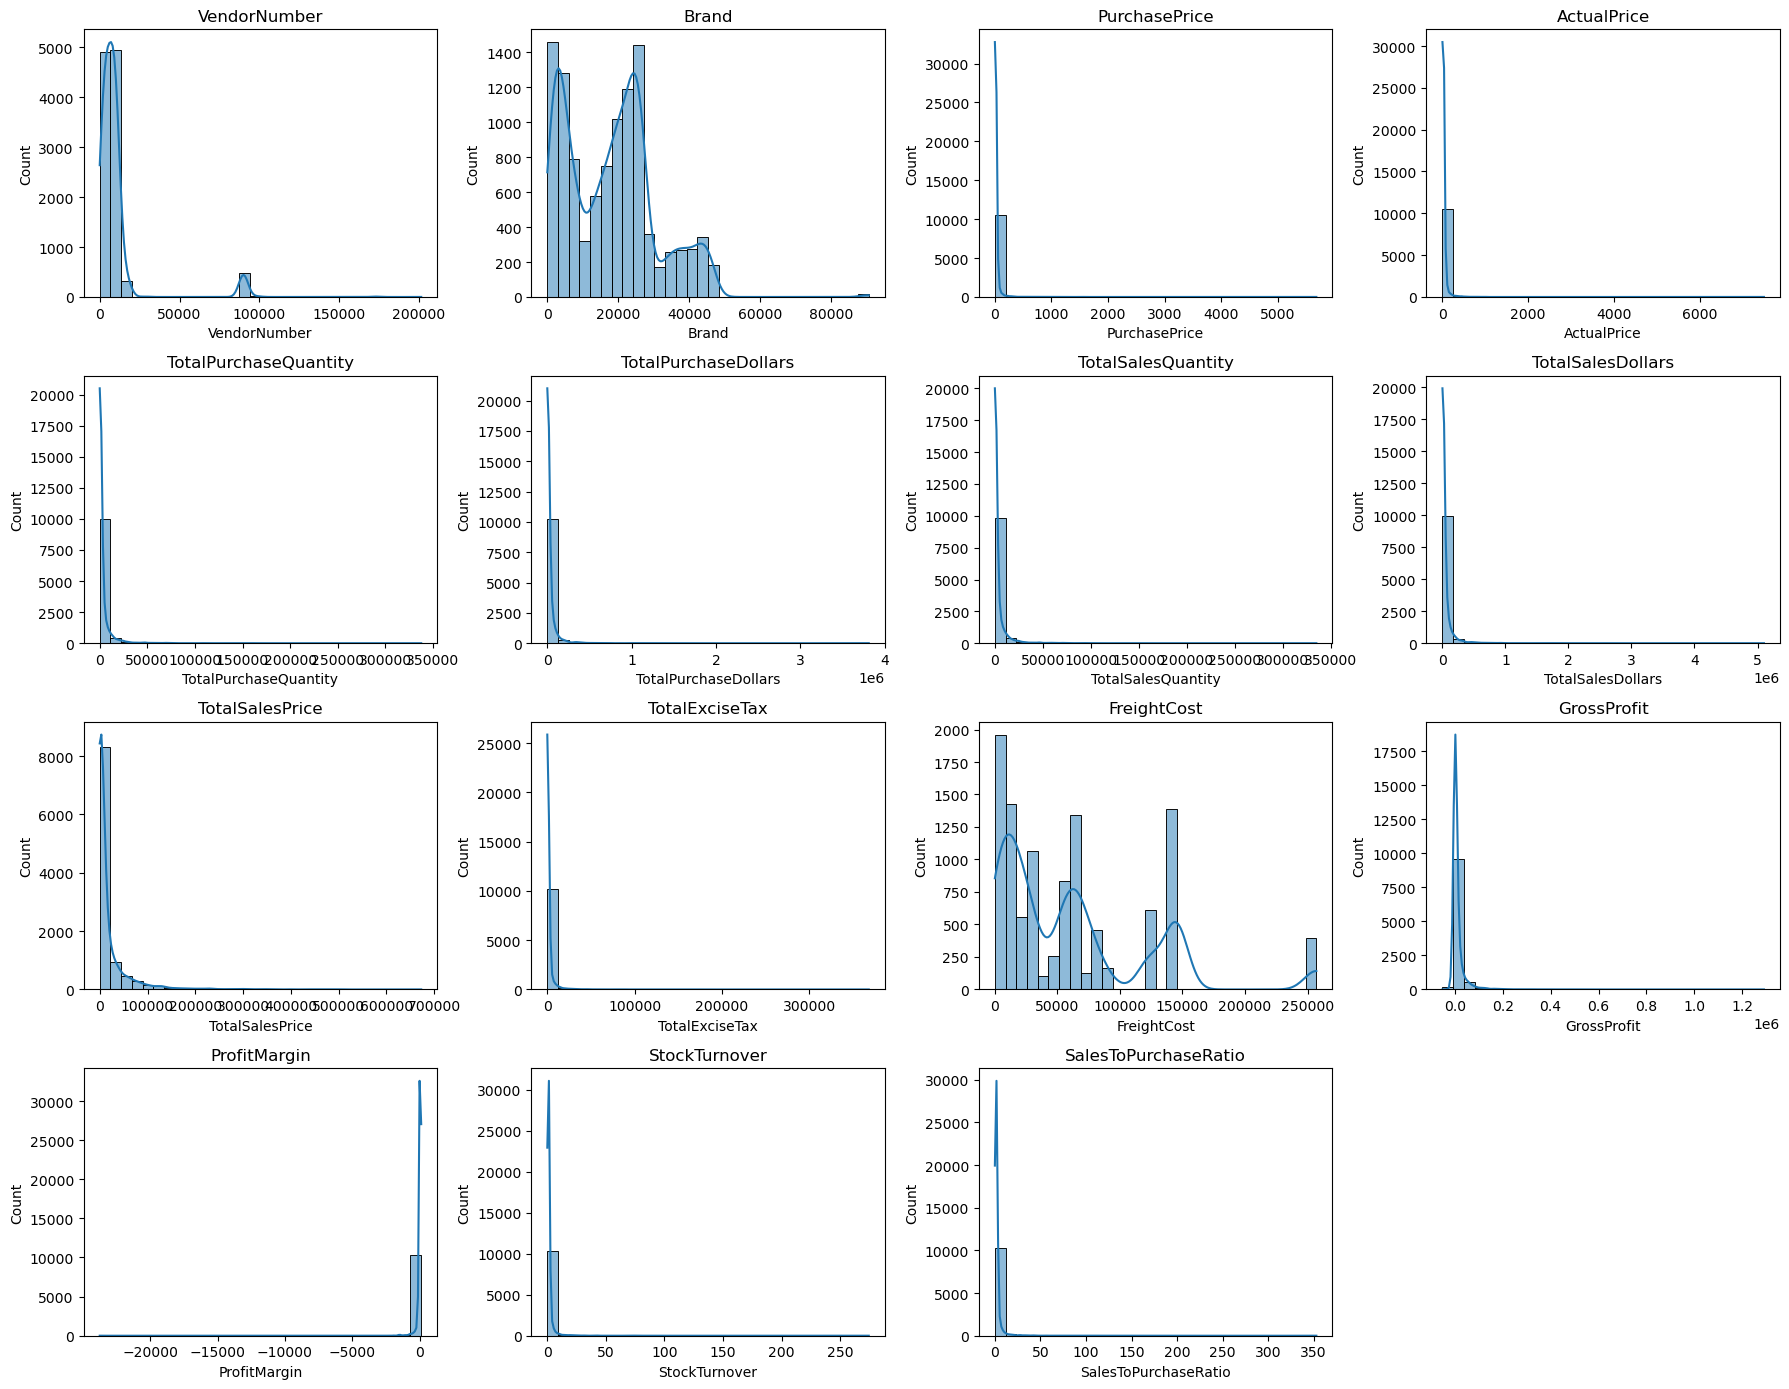

In [25]:
# Distribution plots for numerical columns
numerical_cols = df.select_dtypes(include=np.number).columns

plt.figure(figsize=(18, 14))

for i, col in enumerate(numerical_cols):
    plt.subplot(4, 4, i + 1)
    sns.histplot(data=df, x=col, kde=True, bins=30)
    plt.title(col)

plt.tight_layout()
plt.show()

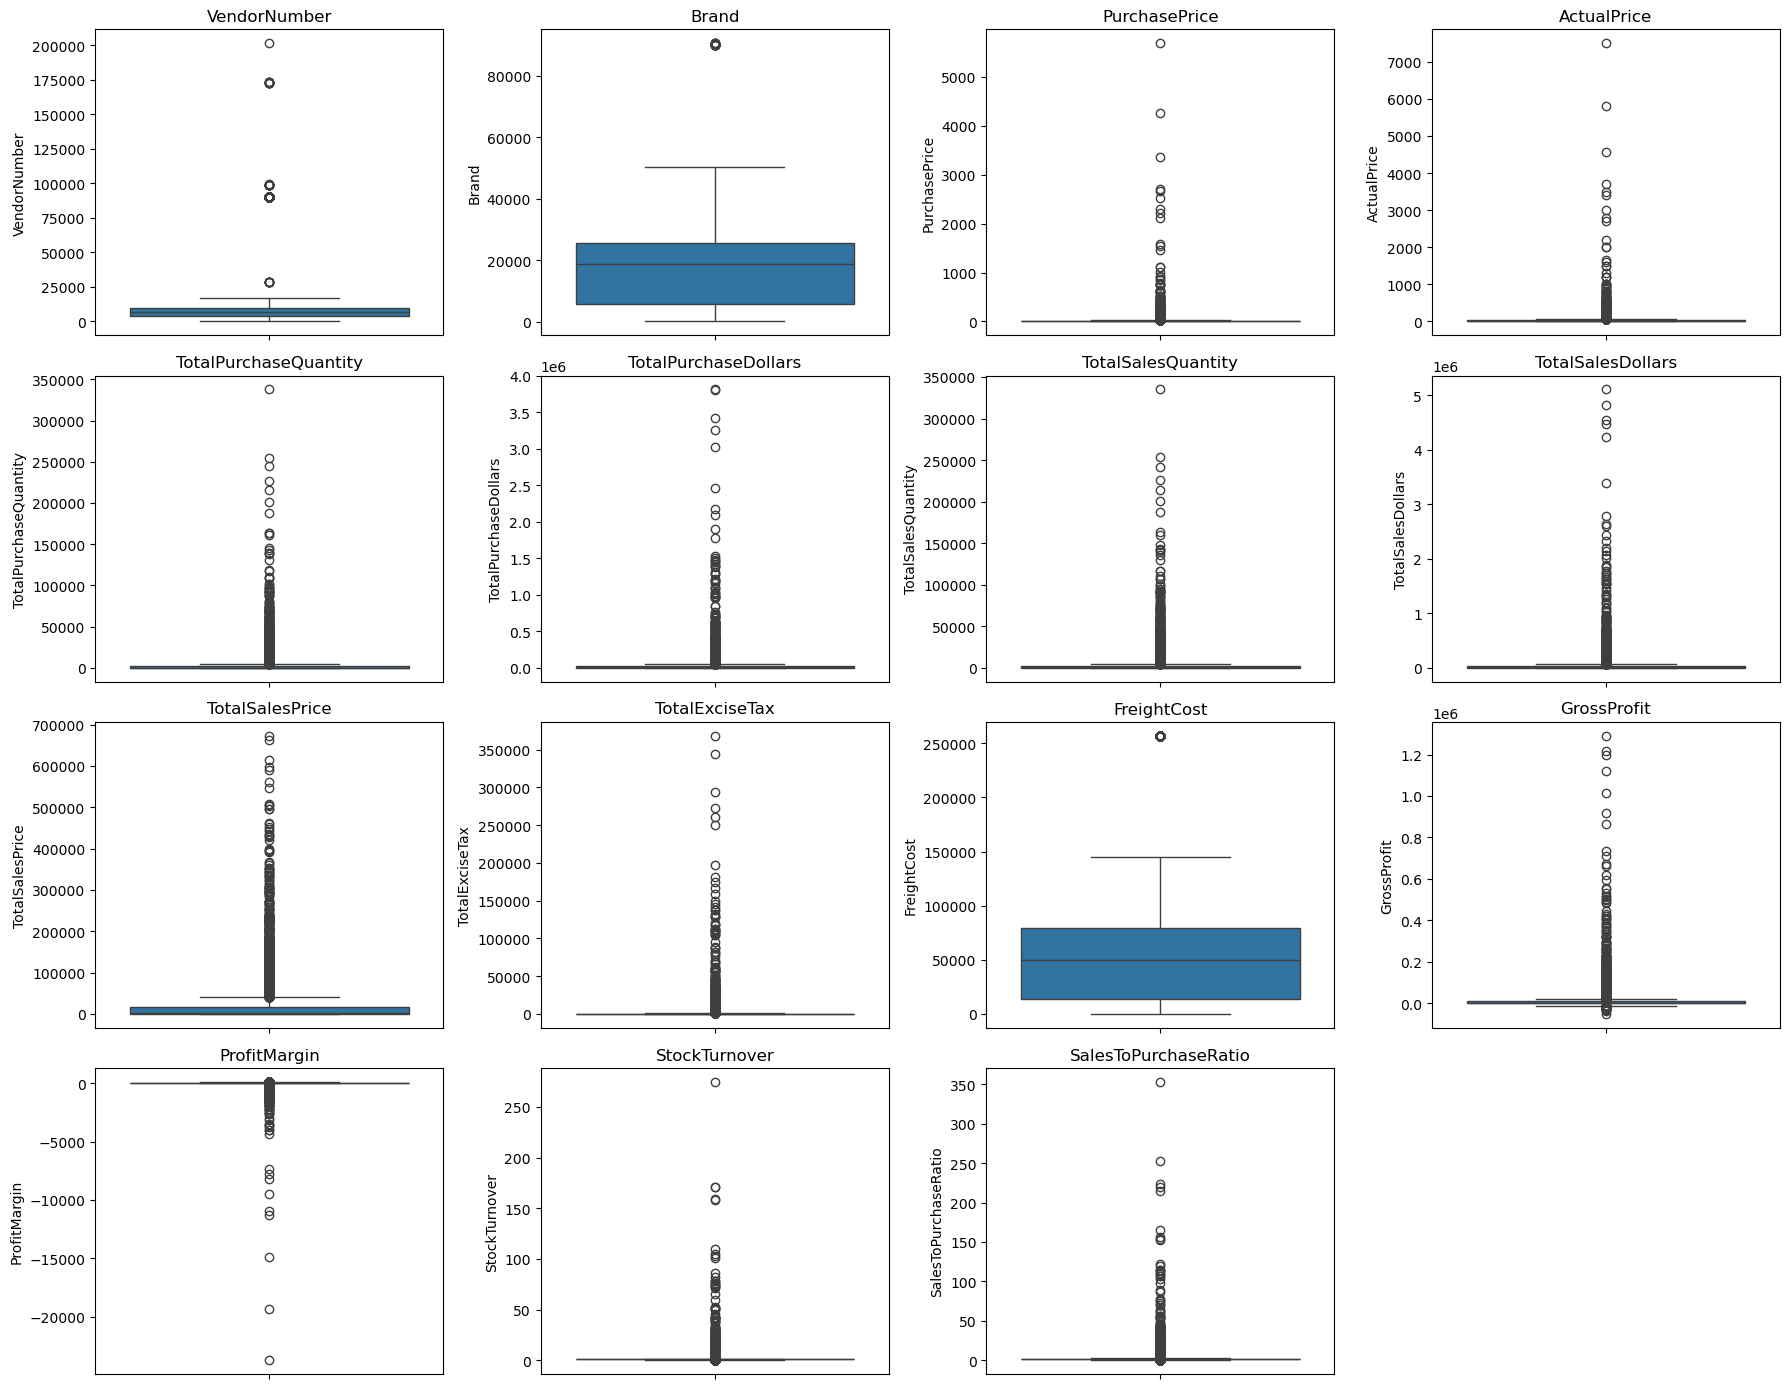

In [26]:
# Outlier detection with boxplots
plt.figure(figsize=(18, 14))

for i, col in enumerate(numerical_cols):
    plt.subplot(4, 4, i + 1)
    sns.boxplot(y=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

In [27]:
# Clean the data for analysi
df = pd.read_sql_query("""
    SELECT *
    FROM vendor_sales_summary
    WHERE GrossProfit > 0
      AND ProfitMargin > 0
      AND TotalSalesQuantity > 0
""", engine)

print("Filtered dataset shape:", df.shape)
display(df.head())

Filtered dataset shape: (8565, 18)


,VendorNumber,VendorName,Brand,Description,PurchasePrice,ActualPrice,Volume,TotalPurchaseQuantity,TotalPurchaseDollars,TotalSalesQuantity,TotalSalesDollars,TotalSalesPrice,TotalExciseTax,FreightCost,GrossProfit,ProfitMargin,StockTurnover,SalesToPurchaseRatio
0,1128,BROWN-FORMAN CORP,1233,Jack Daniels No 7 Black,26.27,36.99,1750,145080.0,3811251.60,142049.0,5.101920e+06,672819.31,260999.20,68601.68,1290667.91,25.297693,0.979108,1.338647
1,4425,MARTIGNETTI COMPANIES,3405,Tito's Handmade Vodka,23.19,28.99,1750,164038.0,3804041.22,160247.0,4.819073e+06,561512.37,294438.66,144929.24,1015032.27,21.062810,0.976890,1.266830
2,17035,PERNOD RICARD USA,8068,Absolut 80 Proof,18.24,24.99,1750,187407.0,3418303.68,187140.0,4.538121e+06,461140.15,343854.07,123780.22,1119816.92,24.675786,0.998575,1.327594
3,3960,DIAGEO NORTH AMERICA INC,4261,Capt Morgan Spiced Rum,16.17,22.99,1750,201682.0,3261197.94,200412.0,4.475973e+06,420050.01,368242.80,257032.07,1214774.94,27.139908,0.993703,1.372493
4,3960,DIAGEO NORTH AMERICA INC,3545,Ketel One Vodka,21.89,29.99,1750,138109.0,3023206.01,135838.0,4.223108e+06,545778.28,249587.83,257032.07,1199901.61,28.412764,0.983556,1.396897


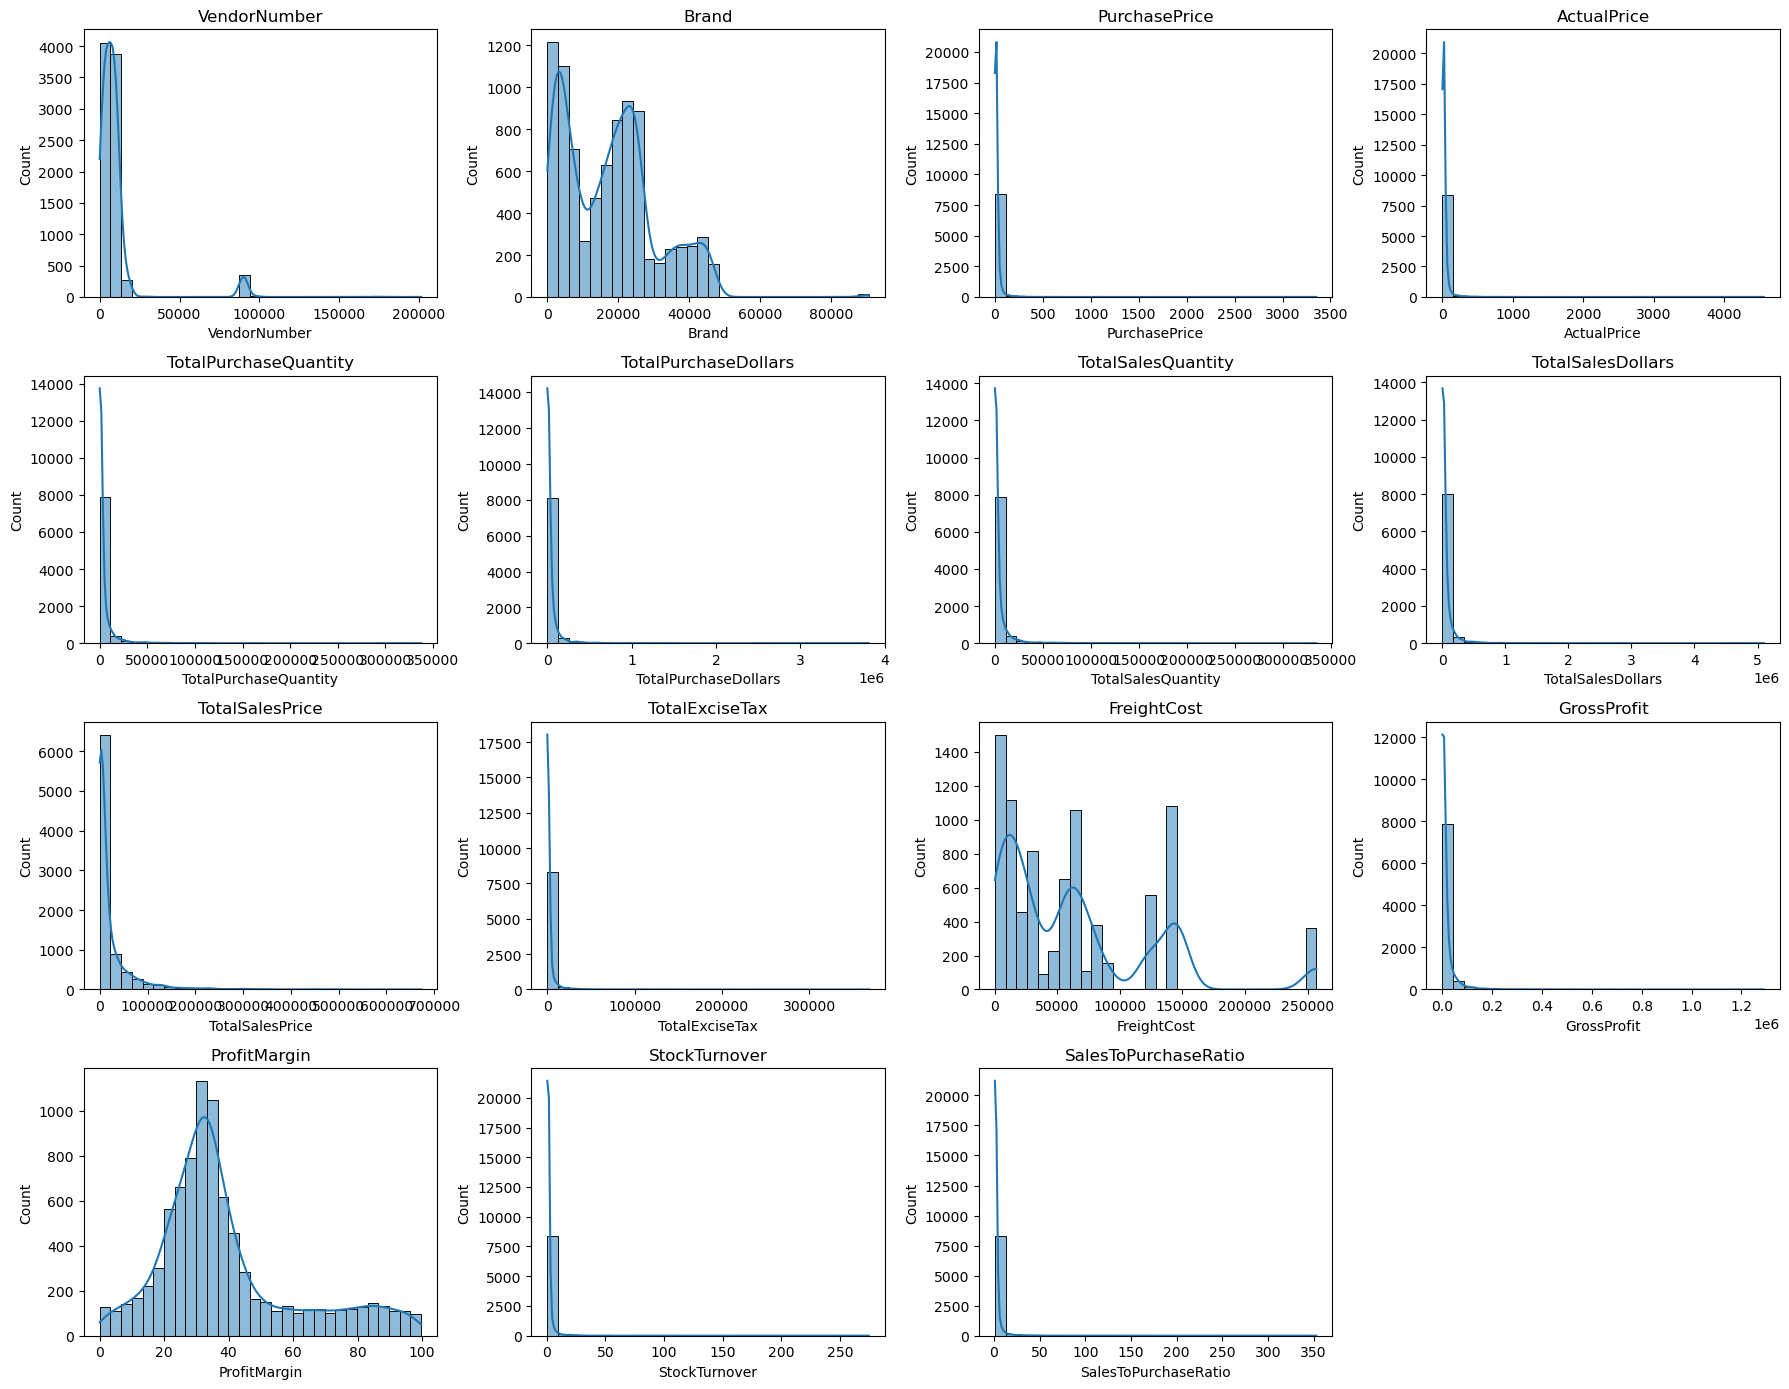

In [28]:
# Distribution plots for numerical columns
numerical_cols = df.select_dtypes(include=np.number).columns

plt.figure(figsize=(18, 14))

for i, col in enumerate(numerical_cols):
    plt.subplot(4, 4, i + 1)
    sns.histplot(data=df, x=col, kde=True, bins=30)
    plt.title(col)

plt.tight_layout()
plt.show()

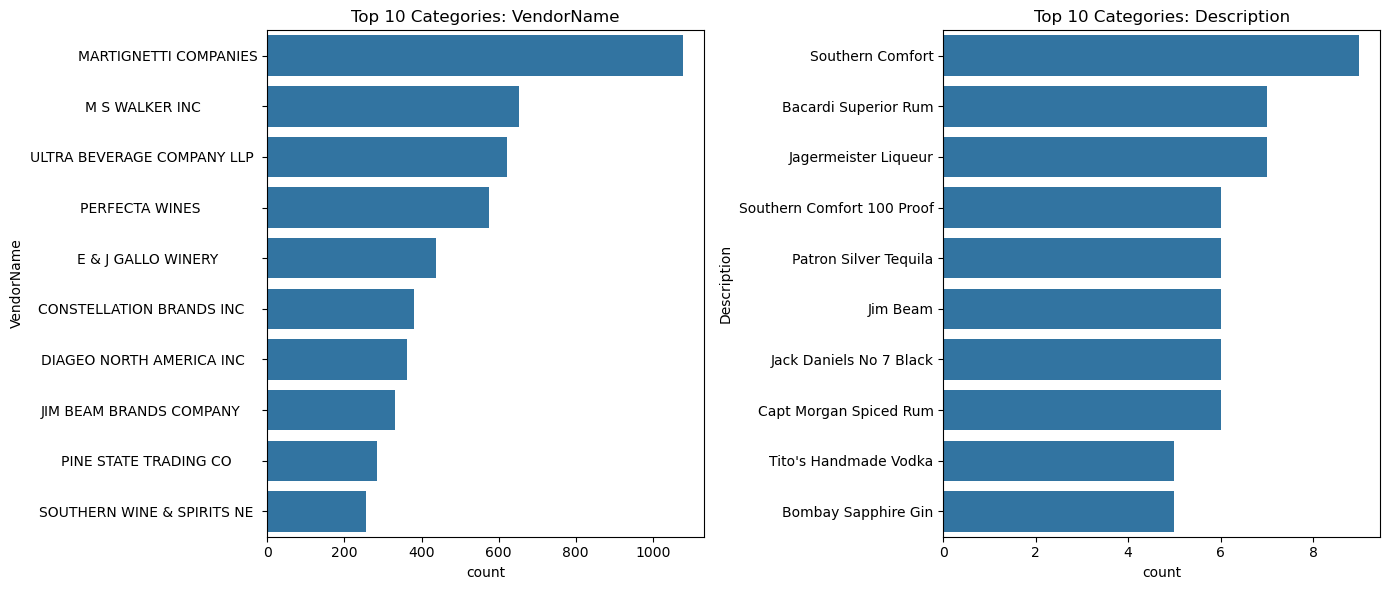

In [29]:
# Count plots for categorical columns
categorical_cols = ["VendorName", "Description"]

plt.figure(figsize=(14, 6))

for i, col in enumerate(categorical_cols):
    plt.subplot(1, 2, i + 1)

    sns.countplot(
        data=df,
        y=col,
        order=df[col].value_counts().head(10).index
    )

    plt.title(f"Top 10 Categories: {col}")

plt.tight_layout()
plt.show()

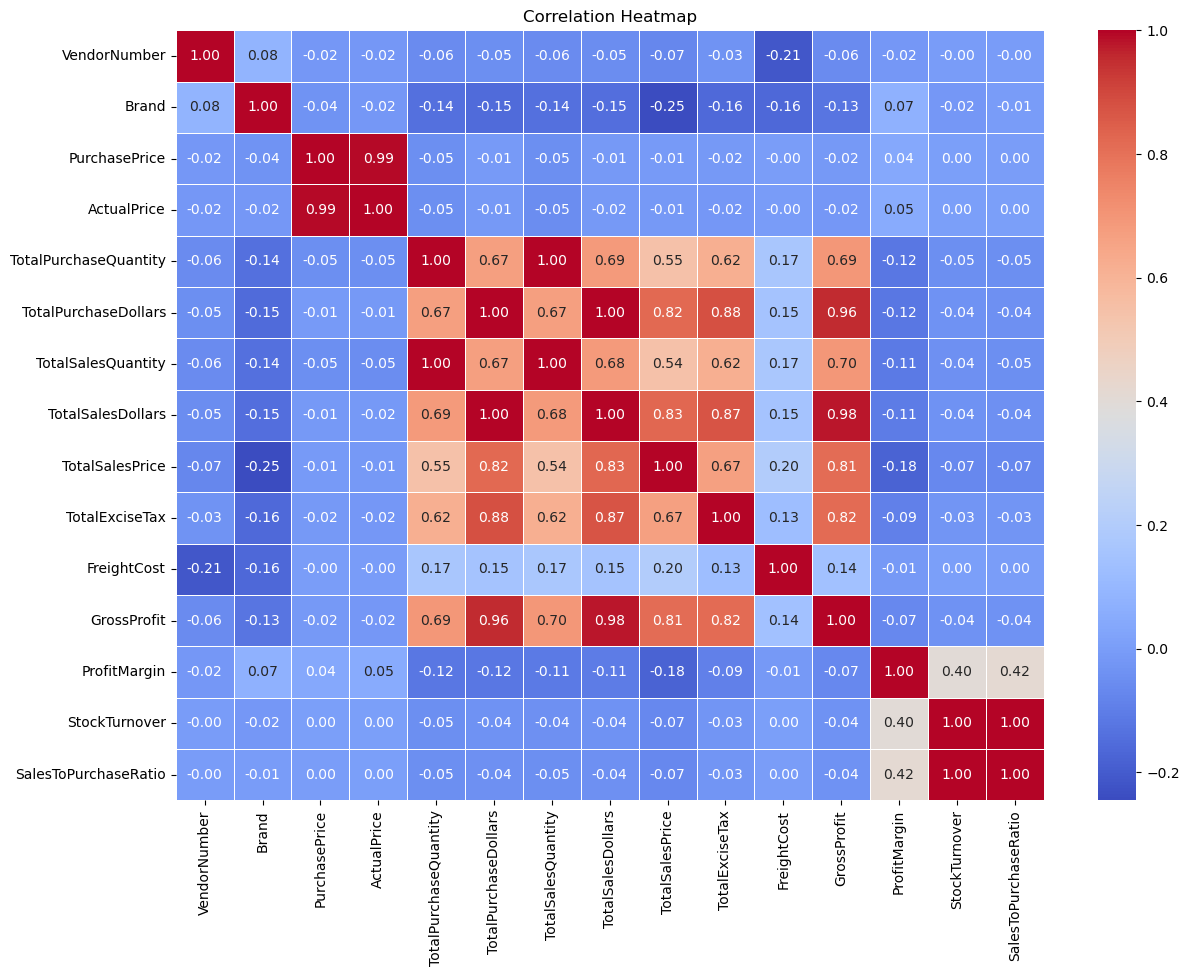

In [30]:
# Correlation heatmap
plt.figure(figsize=(14, 10))

correlation_matrix = df[numerical_cols].corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.show()

# Data Analysis


## Identify Brands tnat need Promotional and Pricing Adjustments which exibits lower sales performance but higher profit margins.

In [31]:
brand_performance = (
    df.groupby("Description")
    .agg({
        "TotalSalesDollars": "sum",
        "ProfitMargin": "mean"
    })
    .reset_index()
)


In [32]:
brand_performance

,Description,TotalSalesDollars,ProfitMargin
0,(RI) 1,21519.09,18.060661
1,.nparalleled Svgn Blanc,1094.63,29.978166
2,10 Span Cab Svgn CC,2703.89,20.937612
3,10 Span Chard CC,3325.56,27.806445
4,10 Span Pnt Gris Monterey Cy,2082.22,32.226182
...,...,...,...
7702,Zorvino Vyds Sangiovese,10579.03,29.525675
7703,Zuccardi Q Malbec,1639.18,23.981503
7704,Zum Rsl,10857.34,32.675038
7705,Zwack Liqueur,227.88,16.653502


In [33]:
low_sales_threshold = brand_performance["TotalSalesDollars"].quantile(0.15)

high_margin_threshold = brand_performance["ProfitMargin"].quantile(0.85)


In [34]:
low_sales_threshold

560.299

In [35]:
high_margin_threshold

64.97017552750111

In [36]:
target_brands = brand_performance[
    (brand_performance["TotalSalesDollars"] <= low_sales_threshold)
    & (brand_performance["ProfitMargin"] >= high_margin_threshold)
]

print("Brands with low sales but high profit margins:")

display(target_brands.sort_values("TotalSalesDollars"))

Brands with low sales but high profit margins:


,Description,TotalSalesDollars,ProfitMargin
6199,Santa Rita Organic Svgn Bl,9.99,66.466466
2369,Debauchery Pnt Nr,11.58,65.975820
2070,Concannon Glen Ellen Wh Zin,15.95,83.448276
2188,Crown Royal Apple,27.86,89.806174
6237,Sauza Sprklg Wild Berry Marg,27.96,82.153076
...,...,...,...
5074,Nanbu Bijin Southern Beauty,535.68,76.747312
2271,Dad's Hat Rye Whiskey,538.89,81.851584
57,A Bichot Clos Marechaudes,539.94,67.740860
6245,Sbragia Home Ranch Merlot,549.75,66.444748


In [37]:
brand_performance = brand_performance['TotalSalesDollars']<10000   #For better visualization

In [39]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate sales and profit margin for each brand
brand_plot_data = df.groupby("Brand", as_index=False).agg(
    TotalSalesDollars=("TotalSalesDollars", "sum"),
    ProfitMargin=("ProfitMargin", "mean")
)

# Set threshold values
high_margin_threshold = brand_plot_data["ProfitMargin"].quantile(0.75)
low_sales_threshold = brand_plot_data["TotalSalesDollars"].quantile(0.25)

# Select target brands: high margin and low sales
target_plot_data = brand_plot_data[
    (brand_plot_data["ProfitMargin"] >= high_margin_threshold) &
    (brand_plot_data["TotalSalesDollars"] <= low_sales_threshold)
].copy()

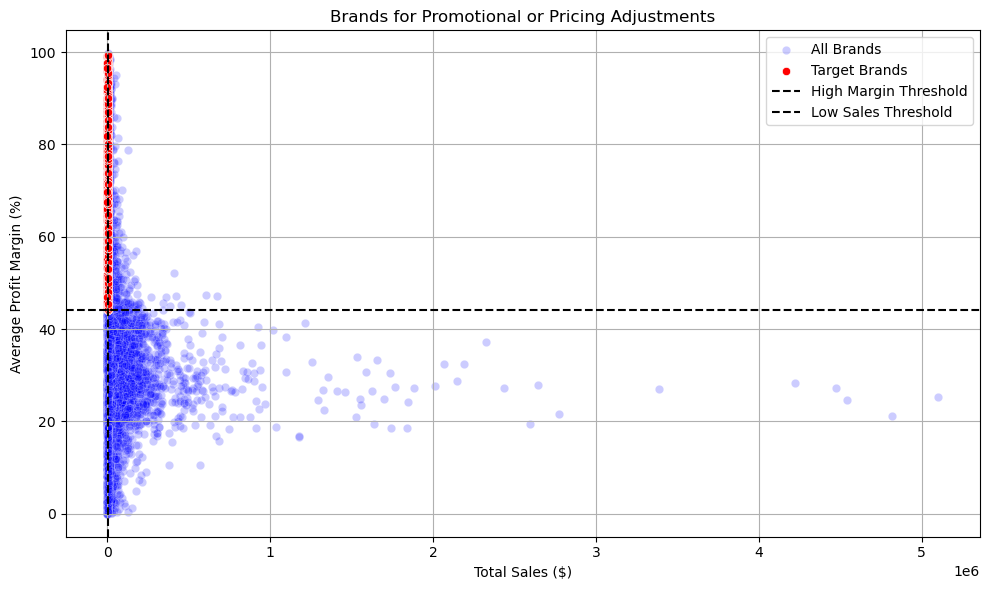

In [40]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=brand_plot_data,
    x="TotalSalesDollars",
    y="ProfitMargin",
    color="blue",
    label="All Brands",
    alpha=0.2
)

sns.scatterplot(
    data=target_plot_data,
    x="TotalSalesDollars",
    y="ProfitMargin",
    color="red",
    label="Target Brands"
)

plt.axhline(
    high_margin_threshold,
    linestyle="--",
    color="black",
    label="High Margin Threshold"
)

plt.axvline(
    low_sales_threshold,
    linestyle="--",
    color="black",
    label="Low Sales Threshold"
)

plt.xlabel("Total Sales ($)")
plt.ylabel("Average Profit Margin (%)")
plt.title("Brands for Promotional or Pricing Adjustments")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## Which Vendors and Brands demonstrate the highest sales performance?

In [41]:
def format_dollars(value):
    if value >= 1_000_000:
        return f"${value / 1_000_000:.2f}M"
    elif value >= 1_000:
        return f"${value / 1_000:.2f}K"
    else:
        return f"${value:.2f}"


In [42]:

top_vendors = (
    df.groupby("VendorName")["TotalSalesDollars"]
    .sum()
    .nlargest(10)
)

top_brands = (
    df.groupby("Description")["TotalSalesDollars"]
    .sum()
    .nlargest(10)
)


In [43]:
print("Top 10 Vendors by Sales")
display(top_vendors)

Top 10 Vendors by Sales


VendorName
DIAGEO NORTH AMERICA INC       6.799010e+07
MARTIGNETTI COMPANIES          3.927640e+07
PERNOD RICARD USA              3.206320e+07
JIM BEAM BRANDS COMPANY        3.142302e+07
BACARDI USA INC                2.485482e+07
CONSTELLATION BRANDS INC       2.421875e+07
E & J GALLO WINERY             1.839990e+07
BROWN-FORMAN CORP              1.824723e+07
ULTRA BEVERAGE COMPANY LLP     1.650254e+07
M S WALKER INC                 1.470646e+07
Name: TotalSalesDollars, dtype: float64

In [44]:
print("Top 10 Brands by Sales")
display(top_brands)

Top 10 Brands by Sales


Description
Jack Daniels No 7 Black    7964746.76
Tito's Handmade Vodka      7399657.58
Grey Goose Vodka           7209608.06
Capt Morgan Spiced Rum     6356320.62
Absolut 80 Proof           6244752.03
Jameson Irish Whiskey      5715759.69
Ketel One Vodka            5070083.56
Baileys Irish Cream        4150122.07
Kahlua                     3604858.66
Tanqueray                  3456697.90
Name: TotalSalesDollars, dtype: float64

In [45]:
top_brands.apply(lambda x : format_dollars(x))

Description
Jack Daniels No 7 Black    $7.96M
Tito's Handmade Vodka      $7.40M
Grey Goose Vodka           $7.21M
Capt Morgan Spiced Rum     $6.36M
Absolut 80 Proof           $6.24M
Jameson Irish Whiskey      $5.72M
Ketel One Vodka            $5.07M
Baileys Irish Cream        $4.15M
Kahlua                     $3.60M
Tanqueray                  $3.46M
Name: TotalSalesDollars, dtype: object

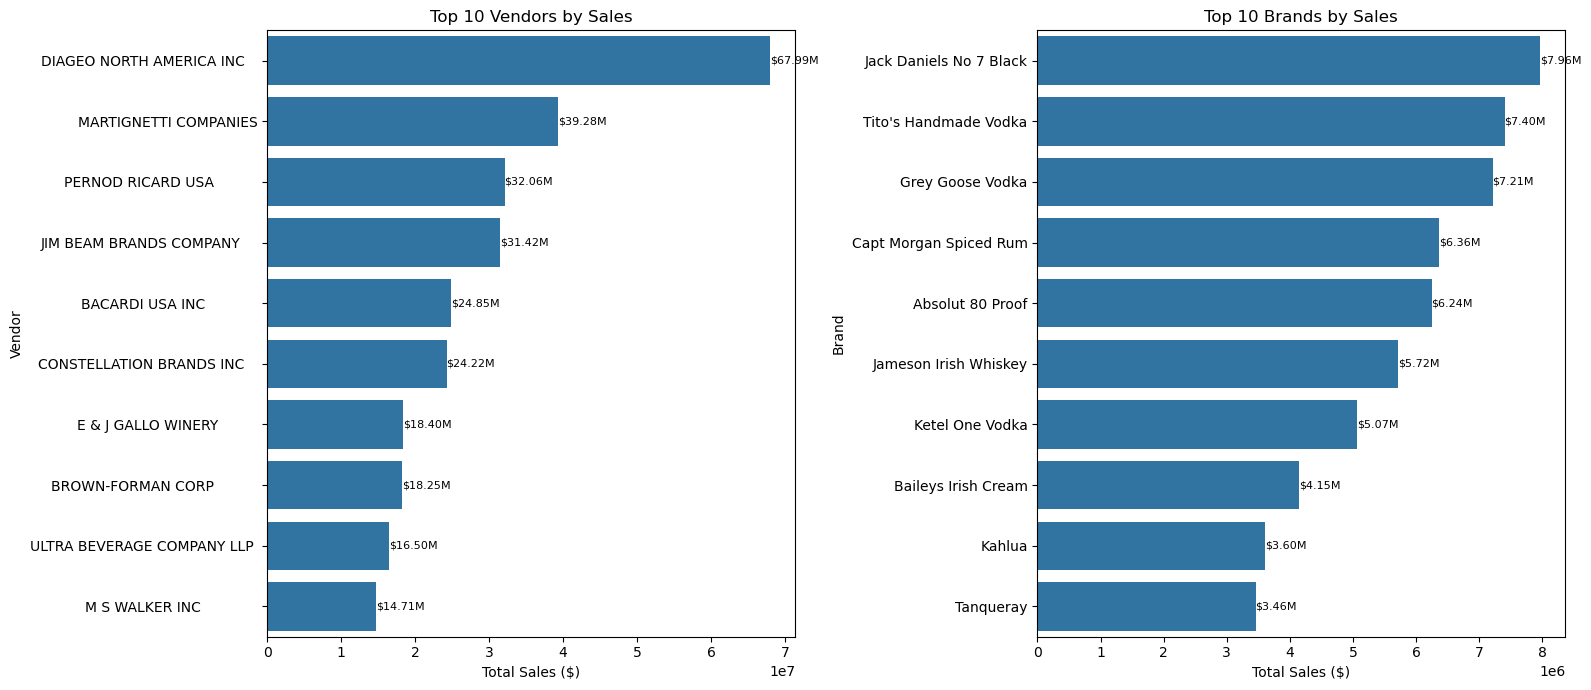

In [46]:
plt.figure(figsize=(16, 7))

# Top vendors
plt.subplot(1, 2, 1)

ax1 = sns.barplot(
    y=top_vendors.index,
    x=top_vendors.values
)

plt.title("Top 10 Vendors by Sales")
plt.xlabel("Total Sales ($)")
plt.ylabel("Vendor")

for bar in ax1.patches:
    ax1.text(
        bar.get_width(),
        bar.get_y() + bar.get_height() / 2,
        format_dollars(bar.get_width()),
        ha="left",
        va="center",
        fontsize=8
    )

# Top brands
plt.subplot(1, 2, 2)

ax2 = sns.barplot(
    y=top_brands.index,
    x=top_brands.values
)

plt.title("Top 10 Brands by Sales")
plt.xlabel("Total Sales ($)")
plt.ylabel("Brand")

for bar in ax2.patches:
    ax2.text(
        bar.get_width(),
        bar.get_y() + bar.get_height() / 2,
        format_dollars(bar.get_width()),
        ha="left",
        va="center",
        fontsize=8
    )

plt.tight_layout()
plt.show()

## Which Vendor contribute the most to total purchase dollars?

In [47]:
vendor_performance = (
    df.groupby("VendorName")
    .agg({
        "TotalPurchaseDollars": "sum",
        "GrossProfit": "sum",
        "TotalSalesDollars": "sum"
    })
    .reset_index()
)
vendor_performance.shape

(120, 4)

In [48]:
vendor_performance

,VendorName,TotalPurchaseDollars,GrossProfit,TotalSalesDollars
0,ADAMBA IMPORTS INTL INC,446.16,258.37,704.53
1,ALISA CARR BEVERAGES,25698.12,78772.82,104470.94
2,ALTAMAR BRANDS LLC,11706.20,4000.61,15706.81
3,AMERICAN SPIRITS EXCHANGE,934.08,577.08,1511.16
4,AMERICAN VINTAGE BEVERAGE,104435.68,35167.85,139603.53
...,...,...,...,...
115,WEIN BAUER INC,42694.64,13522.49,56217.13
116,WESTERN SPIRITS BEVERAGE CO,298416.86,106837.97,405254.83
117,WILLIAM GRANT & SONS INC,5876538.26,1693337.94,7569876.20
118,WINE GROUP INC,5203801.17,3100242.11,8304043.28


In [49]:
vendor_performance["PurchaseContribution%"] = (
    vendor_performance["TotalPurchaseDollars"]
    / vendor_performance["TotalPurchaseDollars"].sum())

In [50]:
vendor_performance

,VendorName,TotalPurchaseDollars,GrossProfit,TotalSalesDollars,PurchaseContribution%
0,ADAMBA IMPORTS INTL INC,446.16,258.37,704.53,0.000001
1,ALISA CARR BEVERAGES,25698.12,78772.82,104470.94,0.000084
2,ALTAMAR BRANDS LLC,11706.20,4000.61,15706.81,0.000038
3,AMERICAN SPIRITS EXCHANGE,934.08,577.08,1511.16,0.000003
4,AMERICAN VINTAGE BEVERAGE,104435.68,35167.85,139603.53,0.000340
...,...,...,...,...,...
115,WEIN BAUER INC,42694.64,13522.49,56217.13,0.000139
116,WESTERN SPIRITS BEVERAGE CO,298416.86,106837.97,405254.83,0.000971
117,WILLIAM GRANT & SONS INC,5876538.26,1693337.94,7569876.20,0.019121
118,WINE GROUP INC,5203801.17,3100242.11,8304043.28,0.016932


In [51]:
vendor_performance = vendor_performance.sort_values(
    "PurchaseContribution%",
    ascending=False
)

display(vendor_performance.head(10).round(2))

,VendorName,TotalPurchaseDollars,GrossProfit,TotalSalesDollars,PurchaseContribution%
25,DIAGEO NORTH AMERICA INC,50097226.16,17892873.26,67990099.42,0.16
57,MARTIGNETTI COMPANIES,25464774.04,13811624.76,39276398.80,0.08
69,PERNOD RICARD USA,23851164.17,8212032.02,32063196.19,0.08
46,JIM BEAM BRANDS COMPANY,23494304.32,7928716.14,31423020.46,0.08
6,BACARDI USA INC,17432020.26,7422796.88,24854817.14,0.06
20,CONSTELLATION BRANDS INC,15273708.08,8945037.57,24218745.65,0.05
11,BROWN-FORMAN CORP,13238939.18,5008291.47,18247230.65,0.04
30,E & J GALLO WINERY,12068539.22,6331360.24,18399899.46,0.04
107,ULTRA BEVERAGE COMPANY LLP,11167081.61,5335462.70,16502544.31,0.04
53,M S WALKER INC,9764312.60,4942145.91,14706458.51,0.03


In [52]:
# Display Top 10 Vendors
top_vendors = vendor_performance.head(10)
top_vendors['TotalSalesDollars'] = top_vendors['TotalSalesDollars'].apply(format_dollars)
top_vendors['TotalPurchaseDollars'] = top_vendors['TotalPurchaseDollars'].apply(format_dollars)
top_vendors['GrossProfit'] = top_vendors['GrossProfit'].apply(format_dollars)
top_vendors

,VendorName,TotalPurchaseDollars,GrossProfit,TotalSalesDollars,PurchaseContribution%
25,DIAGEO NORTH AMERICA INC,$50.10M,$17.89M,$67.99M,0.163003
57,MARTIGNETTI COMPANIES,$25.46M,$13.81M,$39.28M,0.082856
69,PERNOD RICARD USA,$23.85M,$8.21M,$32.06M,0.077605
46,JIM BEAM BRANDS COMPANY,$23.49M,$7.93M,$31.42M,0.076444
6,BACARDI USA INC,$17.43M,$7.42M,$24.85M,0.056719
20,CONSTELLATION BRANDS INC,$15.27M,$8.95M,$24.22M,0.049697
11,BROWN-FORMAN CORP,$13.24M,$5.01M,$18.25M,0.043076
30,E & J GALLO WINERY,$12.07M,$6.33M,$18.40M,0.039268
107,ULTRA BEVERAGE COMPANY LLP,$11.17M,$5.34M,$16.50M,0.036335
53,M S WALKER INC,$9.76M,$4.94M,$14.71M,0.031771


In [53]:
top_vendors ['PurchaseContribution%'].sum()

0.6567741243096852

In [54]:
top_vendors["Cumulative_Contribution%"] = top_vendors["PurchaseContribution%"].cumsum()
top_vendors

,VendorName,TotalPurchaseDollars,GrossProfit,TotalSalesDollars,PurchaseContribution%,Cumulative_Contribution%
25,DIAGEO NORTH AMERICA INC,$50.10M,$17.89M,$67.99M,0.163003,0.163003
57,MARTIGNETTI COMPANIES,$25.46M,$13.81M,$39.28M,0.082856,0.245859
69,PERNOD RICARD USA,$23.85M,$8.21M,$32.06M,0.077605,0.323465
46,JIM BEAM BRANDS COMPANY,$23.49M,$7.93M,$31.42M,0.076444,0.399909
6,BACARDI USA INC,$17.43M,$7.42M,$24.85M,0.056719,0.456628
20,CONSTELLATION BRANDS INC,$15.27M,$8.95M,$24.22M,0.049697,0.506325
11,BROWN-FORMAN CORP,$13.24M,$5.01M,$18.25M,0.043076,0.549401
30,E & J GALLO WINERY,$12.07M,$6.33M,$18.40M,0.039268,0.588669
107,ULTRA BEVERAGE COMPANY LLP,$11.17M,$5.34M,$16.50M,0.036335,0.625004
53,M S WALKER INC,$9.76M,$4.94M,$14.71M,0.031771,0.656774


In [55]:
import pandas as pd
import numpy as np

top_vendors['TotalPurchaseDollars'] = pd.to_numeric(
    top_vendors['TotalPurchaseDollars'],
    errors='coerce'
)

# Remove rows with missing purchase values
top_vendors = top_vendors.dropna(
    subset=['TotalPurchaseDollars']
).copy()

In [56]:
total_purchases = top_vendors['TotalPurchaseDollars'].sum()

if total_purchases != 0:
    top_vendors['Purchase_Contribution%'] = (
        top_vendors['TotalPurchaseDollars'] / total_purchases
    ) * 100
else:
    top_vendors['Purchase_Contribution%'] = 0

top_vendors['Cumulative_Contribution%'] = (
    top_vendors['Purchase_Contribution%'].cumsum()
)

display(top_vendors.head(10))

,VendorName,TotalPurchaseDollars,GrossProfit,TotalSalesDollars,PurchaseContribution%,Cumulative_Contribution%,Purchase_Contribution%


In [57]:
top_vendors = pd.read_sql_query("""
    SELECT
        VendorName,
        SUM(CAST(TotalPurchaseDollars AS DECIMAL(15,2)))
            AS TotalPurchaseDollars
    FROM vendor_sales_summary
    GROUP BY VendorName
    ORDER BY TotalPurchaseDollars DESC
""", engine)

top_vendors['TotalPurchaseDollars'] = pd.to_numeric(
    top_vendors['TotalPurchaseDollars'],
    errors='coerce'
)

total_purchases = top_vendors['TotalPurchaseDollars'].sum()

top_vendors['Purchase_Contribution%'] = (
    top_vendors['TotalPurchaseDollars'] / total_purchases
) * 100

top_vendors['Cumulative_Contribution%'] = (
    top_vendors['Purchase_Contribution%'].cumsum()
)

top_vendors = top_vendors.head(10).copy()

display(top_vendors)

,VendorName,TotalPurchaseDollars,Purchase_Contribution%,Cumulative_Contribution%
0,DIAGEO NORTH AMERICA INC,50959796.85,15.830903,15.830903
1,MARTIGNETTI COMPANIES,27821473.91,8.642873,24.473776
2,JIM BEAM BRANDS COMPANY,24203151.05,7.518824,31.992599
3,PERNOD RICARD USA,24124091.56,7.494263,39.486863
4,BACARDI USA INC,17624378.72,5.475097,44.961960
5,CONSTELLATION BRANDS INC,15573917.90,4.838111,49.800071
6,BROWN-FORMAN CORP,13529433.08,4.202983,54.003054
7,ULTRA BEVERAGE COMPANY LLP,13210613.93,4.103940,58.106994
8,E & J GALLO WINERY,12289608.09,3.817825,61.924819
9,M S WALKER INC,10935817.30,3.397264,65.322082


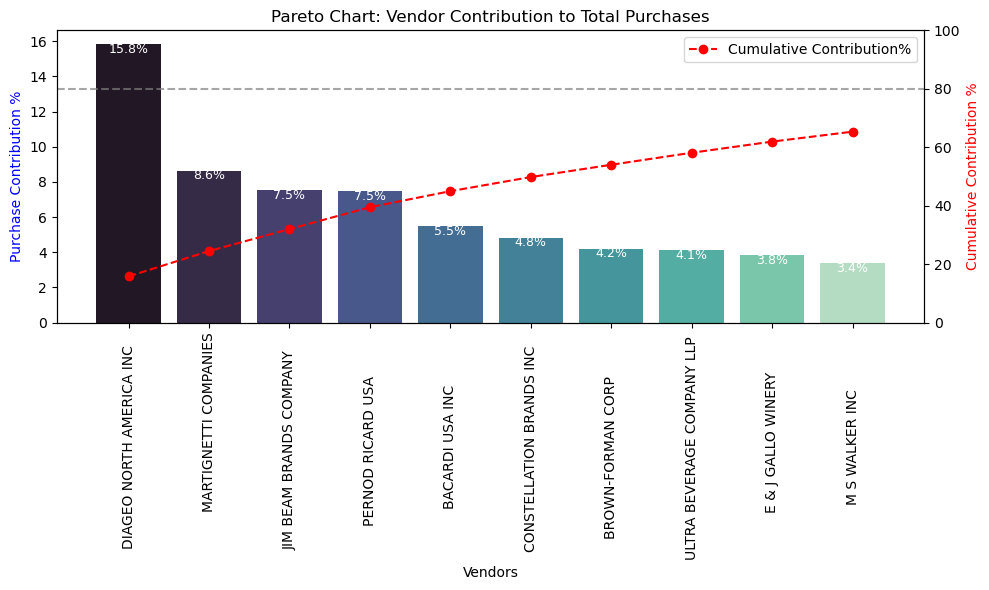

In [58]:
fig, ax1 = plt.subplots(figsize=(10, 6))

# Bar plot for Purchase Contribution%
sns.barplot(
    data=top_vendors,
    x='VendorName',
    y='Purchase_Contribution%',
    hue='VendorName',
    palette="mako",
    legend=False,
    ax=ax1
)

for i, value in enumerate(top_vendors['Purchase_Contribution%']):
    ax1.text(
        i, value - 0.5, f'{value:.1f}%',
        ha='center', fontsize=9, color='white'
    )

# Line plot for Cumulative Contribution%
ax2 = ax1.twinx()

ax2.plot(
    range(len(top_vendors)),
    top_vendors['Cumulative_Contribution%'],
    color='red',
    marker='o',
    linestyle='dashed',
    label='Cumulative Contribution%'
)

ax1.set_xticks(range(len(top_vendors)))
ax1.set_xticklabels(top_vendors['VendorName'], rotation=90)

ax1.set_ylabel('Purchase Contribution %', color='blue')
ax2.set_ylabel('Cumulative Contribution %', color='red')
ax1.set_xlabel('Vendors')
ax1.set_title('Pareto Chart: Vendor Contribution to Total Purchases')

ax2.axhline(y=80, color='gray', linestyle='dashed', alpha=0.7)
ax2.set_ylim(0, 100)
ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()

## How much of total procurement is dependent on the top vendors? 

In [59]:
print(
    f"Total Purchase Contribution of top 10 Vendors is "
    f"{round(top_vendors['Purchase_Contribution%'].sum(), 2)}%"
)

Total Purchase Contribution of top 10 Vendors is 65.32%


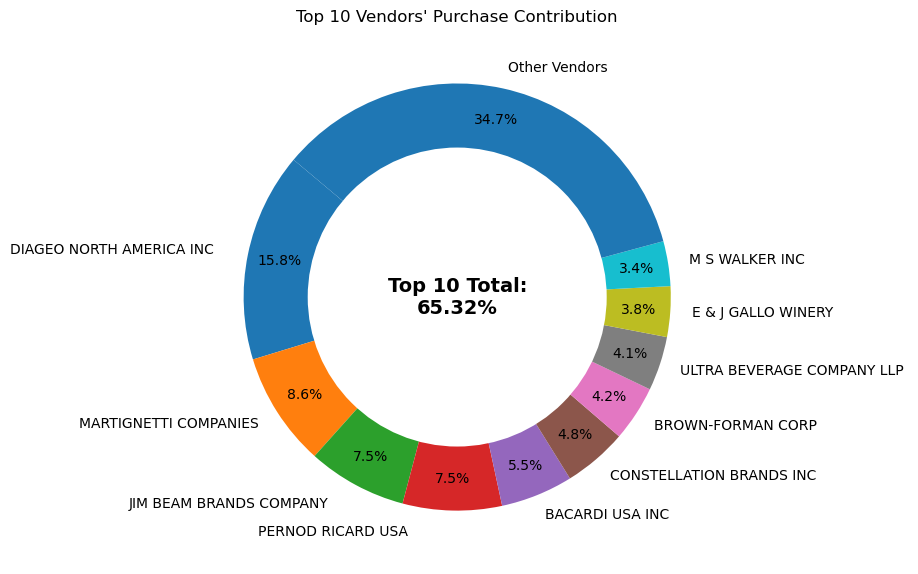

In [60]:
import pandas as pd
import matplotlib.pyplot as plt

# Step 1: Get purchase amount for all vendors from MySQL
top_vendors_purchase = pd.read_sql_query("""
    SELECT
        VendorName,
        SUM(CAST(TotalPurchaseDollars AS DECIMAL(15,2))) AS TotalPurchaseDollars
    FROM vendor_sales_summary
    GROUP BY VendorName
    ORDER BY TotalPurchaseDollars DESC
""", engine)

# Step 2: Calculate each vendor's contribution percentage
total_purchases = top_vendors_purchase["TotalPurchaseDollars"].sum()

top_vendors_purchase["PurchaseContribution%"] = (
    top_vendors_purchase["TotalPurchaseDollars"] / total_purchases
) * 100

# Step 3: Select the top 10 vendors
top_vendors_purchase = top_vendors_purchase.head(10).copy()

vendors = top_vendors_purchase["VendorName"].tolist()
purchase_contributions = top_vendors_purchase["PurchaseContribution%"].tolist()

# Step 4: Calculate contribution of all remaining vendors
remaining_contribution = 100 - sum(purchase_contributions)

vendors.append("Other Vendors")
purchase_contributions.append(remaining_contribution)

# Step 5: Create donut chart
fig, ax = plt.subplots(figsize=(9, 9))

ax.pie(
    purchase_contributions,
    labels=vendors,
    autopct="%1.1f%%",
    startangle=140,
    pctdistance=0.85
)

# Create the hole in the centre
centre_circle = plt.Circle((0, 0), 0.70, fc="white")
ax.add_artist(centre_circle)

# Display top 10 combined contribution
total_contribution = sum(
    top_vendors_purchase["PurchaseContribution%"]
)

plt.text(
    0, 0,
    f"Top 10 Total:\n{total_contribution:.2f}%",
    fontsize=14,
    fontweight="bold",
    ha="center",
    va="center"
)

plt.title("Top 10 Vendors' Purchase Contribution")
plt.tight_layout()
plt.show()

### Does purchasing in bulk reduce the unit price, and what is the optimal purchase volume for cost savings? 

In [61]:
df['UnitPurchasePrice'] = (
    df['TotalPurchaseDollars'] / df['TotalPurchaseQuantity']
)

In [62]:
df["OrderSize"] = pd.qcut(
    df["TotalPurchaseQuantity"],
    q=3,
    labels=["Small", "Medium", "Large"]
)

In [63]:
df.groupby('OrderSize')[['UnitPurchasePrice']].mean()

,UnitPurchasePrice
OrderSize,
Small,39.057543
Medium,15.486414
Large,10.777625


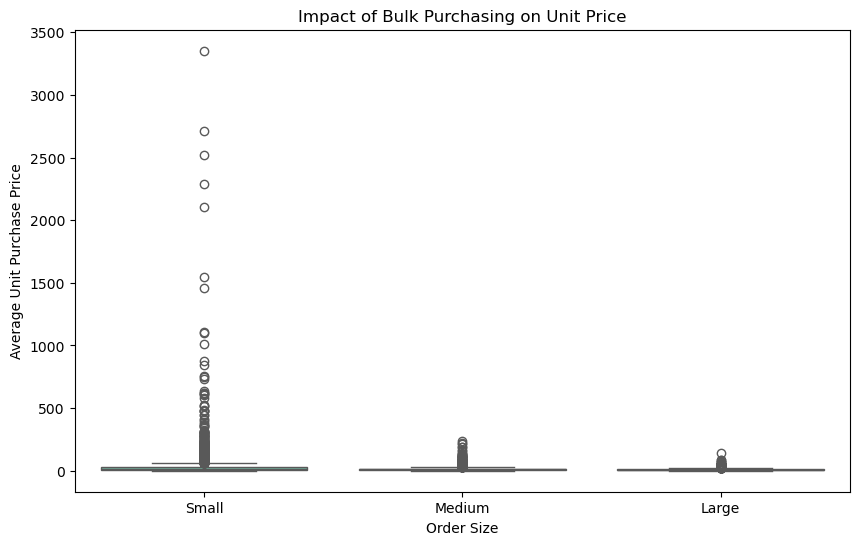

In [64]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="OrderSize",
    y="UnitPurchasePrice",
    palette="Set2"
)

plt.title("Impact of Bulk Purchasing on Unit Price")
plt.xlabel("Order Size")
plt.ylabel("Average Unit Purchase Price")

plt.show()

### Which vendors have low inventory turnover, indicating excess stock and slow moving products?

In [65]:
df[df['StockTurnover']<1].groupby('VendorName')[['StockTurnover']].mean().sort_values('StockTurnover',ascending = True).head(10)

,StockTurnover
VendorName,
ALISA CARR BEVERAGES,0.615385
HIGHLAND WINE MERCHANTS LLC,0.708333
PARK STREET IMPORTS LLC,0.751306
Circa Wines,0.755676
Dunn Wine Brokers,0.766022
CENTEUR IMPORTS LLC,0.773953
SMOKY QUARTZ DISTILLERY LLC,0.783835
TAMWORTH DISTILLING,0.797078
THE IMPORTED GRAPE LLC,0.807569


## How much capital is locked in unsold inventory per vendor, and which vendors contribute the most to it?

In [66]:
df["UnsoldInventoryValue"] = (
    (df["TotalPurchaseQuantity"] - df["TotalSalesQuantity"])
    * df["PurchasePrice"]
)

print(
    'Total Unsold Capital:',
    format_dollars(df["UnsoldInventoryValue"].sum())
)

Total Unsold Capital: $2.71M


In [67]:
# Aggregate Capital Locked per Vendor
inventory_value_per_vendor = (
    df.groupby("VendorName")["UnsoldInventoryValue"]
    .sum()
    .reset_index()
)

# Sort Vendors with the Highest Locked Capital
inventory_value_per_vendor = inventory_value_per_vendor.sort_values(
    by="UnsoldInventoryValue",
    ascending=False
)

inventory_value_per_vendor["UnsoldInventoryValue"] = (
    inventory_value_per_vendor["UnsoldInventoryValue"].apply(format_dollars)
)

inventory_value_per_vendor.head(10)

,VendorName,UnsoldInventoryValue
25,DIAGEO NORTH AMERICA INC,$722.21K
46,JIM BEAM BRANDS COMPANY,$554.67K
69,PERNOD RICARD USA,$470.63K
117,WILLIAM GRANT & SONS INC,$401.96K
30,E & J GALLO WINERY,$228.28K
80,SAZERAC CO INC,$198.44K
11,BROWN-FORMAN CORP,$177.73K
20,CONSTELLATION BRANDS INC,$133.62K
62,MOET HENNESSY USA INC,$126.48K
78,REMY COINTREAU USA INC,$118.60K


## What is the 95% confidence intervals for profit margins of top-performing and low-performing vendors.

In [77]:
top_threshold = df["TotalSalesDollars"].quantile(0.75)
low_threshold = df["TotalSalesDollars"].quantile(0.25)


In [78]:
top_vendor_margins = df.loc[
    df["TotalSalesDollars"] >= top_threshold,
    "ProfitMargin"
].dropna()

low_vendor_margins = df.loc[
    df["TotalSalesDollars"] <= low_threshold,
    "ProfitMargin"
].dropna()

In [79]:
top_vendor_margins

0       25.297693
1       21.062810
2       24.675786
3       27.139908
4       28.412764
          ...    
3523    79.684817
3681    85.782102
4751    93.085860
4920    95.012530
5050    94.271857
Name: ProfitMargin, Length: 2142, dtype: float64

In [80]:
low_vendor_margins

5631     4.111764
5652     6.145626
5701    12.007271
5704     1.677308
5724     7.239599
          ...    
8560    83.448276
8561    96.436186
8562    25.252525
8563    98.974037
8564    99.166079
Name: ProfitMargin, Length: 2142, dtype: float64

In [81]:
def confidence_interval(data, confidence=0.95):
    mean_val = np.mean(data)
    std_err = np.std(data, ddof=1) / np.sqrt(len(data))

    t_critical = stats.t.ppf(
        (1 + confidence) / 2,
        df=len(data) - 1
    )

    margin_of_error = t_critical * std_err

    return (
        mean_val,
        mean_val - margin_of_error,
        mean_val + margin_of_error
    )


Top vendors 95% CI: (30.74, 31.61), Mean: 31.17
Low vendors 95% CI: (40.48, 42.62), Mean: 41.55


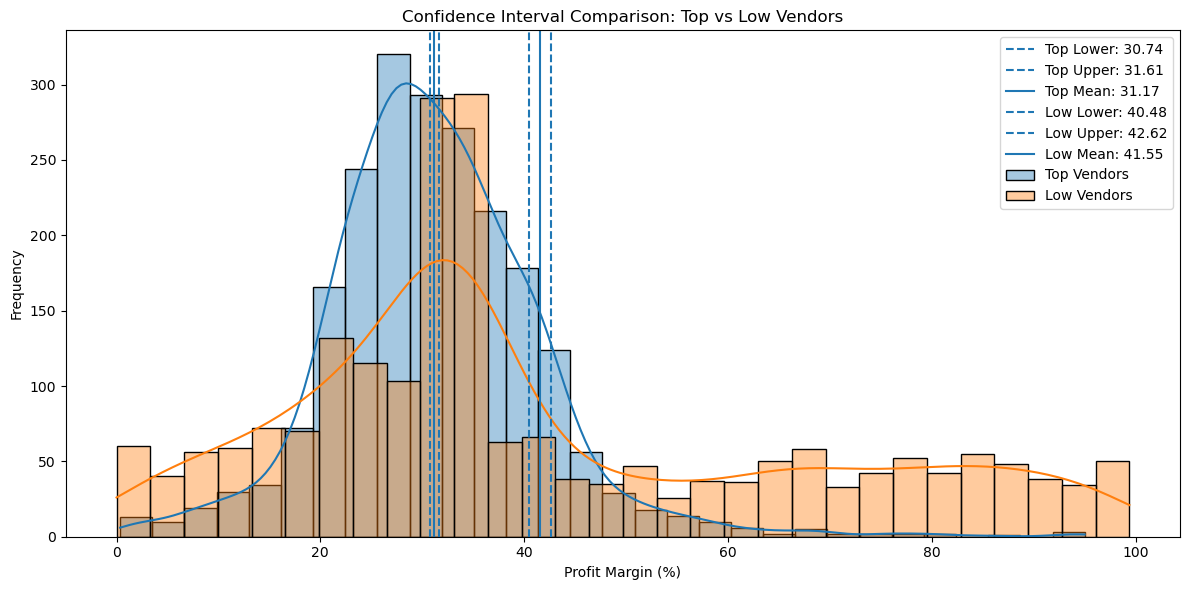

In [82]:
top_mean, top_lower, top_upper = confidence_interval(top_vendor)
low_mean, low_lower, low_upper = confidence_interval(low_vendor)

print(
    f"Top vendors 95% CI: ({top_lower:.2f}, {top_upper:.2f}), "
    f"Mean: {top_mean:.2f}"
)

print(
    f"Low vendors 95% CI: ({low_lower:.2f}, {low_upper:.2f}), "
    f"Mean: {low_mean:.2f}"
)
plt.figure(figsize=(12, 6))

sns.histplot(
    top_vendor_margins,
    kde=True,
    bins=30,
    alpha=0.4,
    label="Top Vendors"
)

plt.axvline(top_lower, linestyle="--", label=f"Top Lower: {top_lower:.2f}")
plt.axvline(top_upper, linestyle="--", label=f"Top Upper: {top_upper:.2f}")
plt.axvline(top_mean, linestyle="-", label=f"Top Mean: {top_mean:.2f}")

sns.histplot(
    low_vendor_margins,
    kde=True,
    bins=30,
    alpha=0.4,
    label="Low Vendors"
)

plt.axvline(low_lower, linestyle="--", label=f"Low Lower: {low_lower:.2f}")
plt.axvline(low_upper, linestyle="--", label=f"Low Upper: {low_upper:.2f}")
plt.axvline(low_mean, linestyle="-", label=f"Low Mean: {low_mean:.2f}")

plt.title("Confidence Interval Comparison: Top vs Low Vendors")
plt.xlabel("Profit Margin (%)")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()

## Is there a significant difference in profit margins between top-performing and low-performing vendors?

### Hypothesis:

**H₀ (Null Hypothesis):** There is no significant difference in the mean profit margins of top-performing and low-performing vendors.

**H₁ (Alternative Hypothesis):** The mean profit margins of top-performing and low-performing vendors are significantly different.

In [84]:
t_stat, p_value = ttest_ind(
    top_vendor_margins,
    low_vendor_margins,
    equal_var=False
)

print(f"T-Statistic: {t_stat:.4f}")
print(f"P-Value: {p_value:.4f}")

if p_value < 0.05:
    print(
        "Reject the null hypothesis: There is a statistically "
        "significant difference in profit margins."
    )
else:
    print(
        "Fail to reject the null hypothesis: There is insufficient "
        "evidence of a significant difference in profit margins."
    )

T-Statistic: -17.6440
P-Value: 0.0000
Reject the null hypothesis: There is a statistically significant difference in profit margins.


In [85]:
df.to_csv("vendor_sales_summary.csv", index=False)

In [86]:
import os

print(os.getcwd())

C:\Users\HP\data
